# EDA dataset: intent và object detection

Notebook này khảo sát hai nguồn dữ liệu trong project:
- `data/intent_train.csv`, `data/intent_test.csv`: câu hỏi tiếng Việt và nhãn intent.
- `data/train/labels`, `data/test/images`: ảnh và nhãn bounding box theo định dạng YOLO.

Mục tiêu: kiểm tra schema, missing/duplicate, phân bố nhãn, chất lượng bbox và trực quan hóa dữ liệu.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from IPython.display import display

sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams['figure.figsize'] = (10, 5)
pd.set_option('display.max_colwidth', 120)

ROOT = Path.cwd()
DATA = ROOT / 'data'
TRAIN_CSV = DATA / 'intent_train.csv'
TEST_CSV = DATA / 'intent_test.csv'
CLASSES_FILE = DATA / 'classes.txt'
LABEL_DIR = DATA / 'train' / 'labels'
TRAIN_IMAGE_DIR = DATA / 'train' / 'images'
IMAGE_DIR = DATA / 'test' / 'images'

# Khi notebook được mở từ một thư mục con, tìm lại root có thư mục data.
if not DATA.exists():
    for parent in Path.cwd().parents:
        if (parent / 'data').exists():
            ROOT, DATA = parent, parent / 'data'
            TRAIN_CSV, TEST_CSV = DATA / 'intent_train.csv', DATA / 'intent_test.csv'
            CLASSES_FILE = DATA / 'classes.txt'
            LABEL_DIR, TRAIN_IMAGE_DIR, IMAGE_DIR = DATA / 'train' / 'labels', DATA / 'train' / 'images', DATA / 'test' / 'images'
            break

train_df = pd.read_csv(TRAIN_CSV)
test_df = pd.read_csv(TEST_CSV)
classes = [x.strip() for x in CLASSES_FILE.read_text(encoding='utf-8').splitlines() if x.strip()]
print(f'Root: {ROOT}')
print(f'Intent train: {train_df.shape}, intent test: {test_df.shape}')
print(f'Classes ({len(classes)}): {classes}')
print(f"YOLO label files: {len(list(LABEL_DIR.glob('*.txt'))):,}")
print(f"Train images: {len(list(TRAIN_IMAGE_DIR.glob('*.png'))):,}")
print(f"Test images: {len(list(IMAGE_DIR.glob('*.png'))):,}")

Root: c:\Users\admin\OneDrive - The University of Technology\Desktop\edge_ai
Intent train: (6000, 3), intent test: (4000, 2)
Classes (7): ['bottle', 'cup', 'phone', 'book', 'mouse', 'box', 'toy_car']
YOLO label files: 6,000
Train images: 6,000
Test images: 4,000


## 1. Intent dataset: schema, missing và duplicate

In [2]:
display(train_df.head())
display(train_df.info())
summary = pd.DataFrame({
    'dtype': train_df.dtypes.astype(str),
    'missing_count': train_df.isna().sum(),
    'missing_pct': (train_df.isna().mean() * 100).round(2),
    'n_unique': train_df.nunique(dropna=False),
})
display(summary)
print('Duplicate rows:', train_df.duplicated().sum())
print('Duplicate question_id:', train_df['question_id'].duplicated().sum())
print('Duplicate question:', train_df['question'].duplicated().sum())
print('Test missing values:', int(test_df.isna().sum().sum()))

,question_id,question,intent
0,tq_0001,"Vi tri thung giay so voi khung hinh la trai, giua hay phai?",LOCATION
1,tq_0002,"Cho biet chai o ben trai, giua hay ben phai.",LOCATION
2,tq_0003,"Cho toi hoi, coc nay dung de uong ca phe hay tra nhi?",OUT_OF_SCOPE
3,tq_0004,Co duoc bao nhieu chai nuoc trong anh?,COUNT
4,tq_0005,"Xin hoi, trong hinh nay co coc uong nuoc khong?",EXIST


<class 'pandas.DataFrame'>
RangeIndex: 6000 entries, 0 to 5999
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   question_id  6000 non-null   str  
 1   question     6000 non-null   str  
 2   intent       6000 non-null   str  
dtypes: str(3)
memory usage: 507.0 KB


None

,dtype,missing_count,missing_pct,n_unique
question_id,str,0,0.0,6000
question,str,0,0.0,6000
intent,str,0,0.0,5


Duplicate rows: 0
Duplicate question_id: 0
Duplicate question: 0
Test missing values: 0


## 2. Số lượng mẫu của mỗi nhãn (intent)

,intent,count,percentage
0,LOCATION,1200,20.0
1,OUT_OF_SCOPE,1200,20.0
2,COUNT,1200,20.0
3,EXIST,1200,20.0
4,LIST,1200,20.0


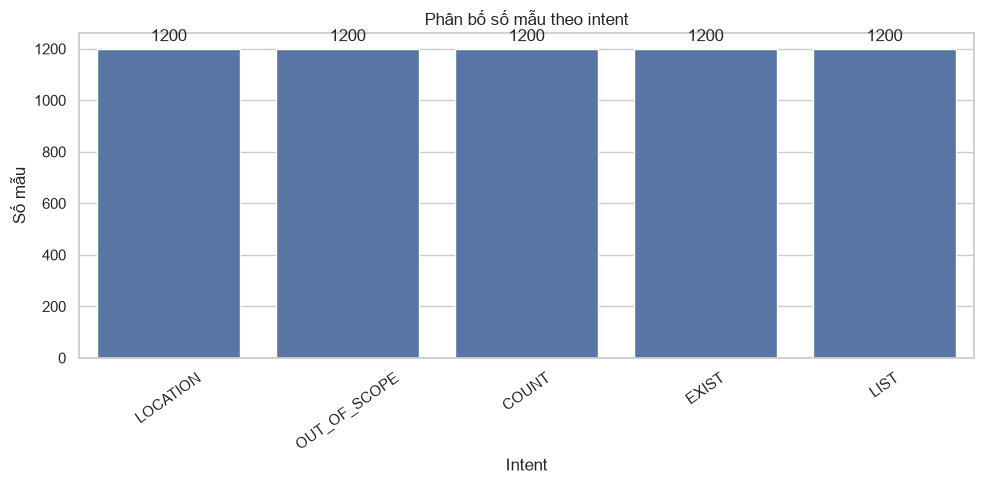

Số intent: 5
Tỉ lệ lớp lớn nhất/nhỏ nhất: 1.0


In [3]:
label_counts = train_df['intent'].value_counts().rename_axis('intent').reset_index(name='count')
label_counts['percentage'] = (label_counts['count'] / len(train_df) * 100).round(2)
display(label_counts)

plt.figure(figsize=(10, 5))
ax = sns.barplot(data=label_counts, x='intent', y='count', order=label_counts['intent'])
ax.set(title='Phân bố số mẫu theo intent', xlabel='Intent', ylabel='Số mẫu')
ax.tick_params(axis='x', rotation=35)
for container in ax.containers:
    ax.bar_label(container, fmt='%d', padding=3)
plt.tight_layout()
plt.show()

print('Số intent:', train_df['intent'].nunique())
print('Tỉ lệ lớp lớn nhất/nhỏ nhất:', round(label_counts['count'].max() / label_counts['count'].min(), 2))

,question_len_chars,question_len_words
count,6000.00,6000.00
mean,48.71,10.83
std,11.36,2.52
min,14.00,4.00
25%,41.00,9.00
50%,48.00,11.00
75%,56.00,13.00
max,88.00,21.00


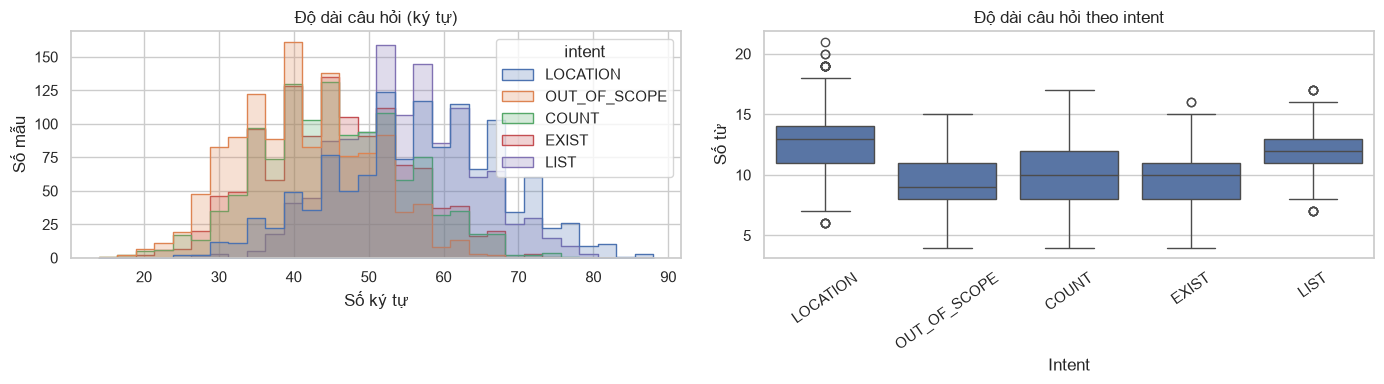

In [4]:
train_df['question_len_chars'] = train_df['question'].fillna('').str.len()
train_df['question_len_words'] = train_df['question'].fillna('').str.split().str.len()
display(train_df[['question_len_chars', 'question_len_words']].describe().round(2))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(data=train_df, x='question_len_chars', hue='intent', bins=30, element='step', common_norm=False, ax=axes[0])
axes[0].set(title='Độ dài câu hỏi (ký tự)', xlabel='Số ký tự', ylabel='Số mẫu')
sns.boxplot(data=train_df, x='intent', y='question_len_words', ax=axes[1])
axes[1].set(title='Độ dài câu hỏi theo intent', xlabel='Intent', ylabel='Số từ')
axes[1].tick_params(axis='x', rotation=35)
plt.tight_layout()
plt.show()

## 3. YOLO labels: kiểm tra class, missing label và bbox

In [5]:
def read_yolo_labels(label_dir, class_names):
    rows, errors = [], []
    for path in sorted(Path(label_dir).glob('*.txt')):
        raw_lines = [line.strip() for line in path.read_text(encoding='utf-8').splitlines() if line.strip()]
        if not raw_lines:
            rows.append({'file': path.name, 'object_index': np.nan, 'class_id': np.nan, 'class_name': '(empty)', 'cx': np.nan, 'cy': np.nan, 'w': np.nan, 'h': np.nan, 'valid': True})
            continue
        for i, line in enumerate(raw_lines):
            parts = line.split()
            try:
                values = list(map(float, parts))
                valid_format = len(values) == 5
                class_id = int(values[0]) if values else np.nan
                coords = values[1:] if len(values) == 5 else [np.nan] * 4
                valid = valid_format and 0 <= class_id < len(class_names) and all(0 <= x <= 1 for x in coords) and coords[2] > 0 and coords[3] > 0
                rows.append({'file': path.name, 'object_index': i, 'class_id': class_id, 'class_name': class_names[class_id] if 0 <= class_id < len(class_names) else '(invalid)', 'cx': coords[0], 'cy': coords[1], 'w': coords[2], 'h': coords[3], 'valid': valid})
                if not valid: errors.append((path.name, i, line))
            except (ValueError, IndexError):
                errors.append((path.name, i, line))
    return pd.DataFrame(rows), errors

boxes_df, label_errors = read_yolo_labels(LABEL_DIR, classes)
image_files = {p.stem for p in TRAIN_IMAGE_DIR.glob('*.png')}
label_files = set(boxes_df['file'].str.replace('.txt', '', regex=False))
print(f'Tổng object annotations: {len(boxes_df):,}')
print(f"File nhãn rỗng: {(boxes_df.class_name == '(empty)').sum():,}")
print(f'Dòng nhãn sai format/range: {len(label_errors):,}')
print(f'Class id xuất hiện: {sorted(boxes_df[boxes_df.class_id.notna()].class_id.astype(int).unique())}')
print(f'Ảnh test không có nhãn train tương ứng (không nhất thiết là lỗi): {len(image_files - label_files):,}')
display(boxes_df.head())

Tổng object annotations: 38,774
File nhãn rỗng: 0
Dòng nhãn sai format/range: 0
Class id xuất hiện: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6)]
Ảnh test không có nhãn train tương ứng (không nhất thiết là lỗi): 0


,file,object_index,class_id,class_name,cx,cy,w,h,valid
0,00001.txt,0,1,cup,0.559375,0.295833,0.093750,0.116667,True
1,00001.txt,1,3,book,0.235937,0.793750,0.303125,0.212500,True
2,00001.txt,2,6,toy_car,0.801562,0.356250,0.078125,0.087500,True
3,00001.txt,3,5,box,0.257812,0.472917,0.296875,0.379167,True
4,00001.txt,4,2,phone,0.590625,0.652083,0.131250,0.295833,True


,class_name,objects
0,bottle,5798
1,cup,5707
2,phone,5728
3,book,5199
4,mouse,5510
5,box,5121
6,toy_car,5711


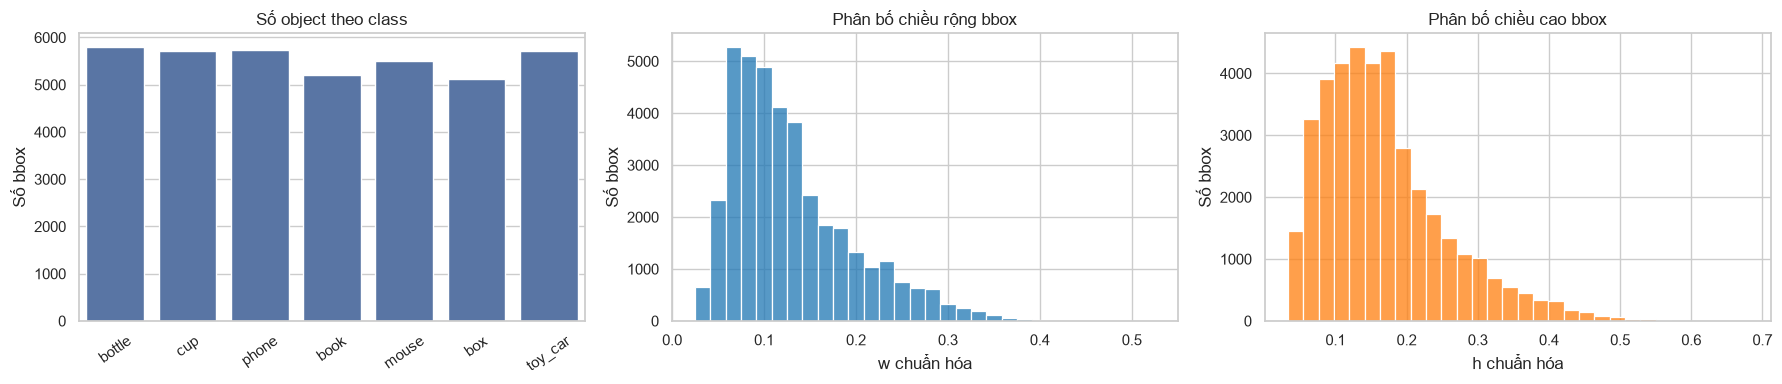

,cx,cy,w,h,area
count,38774.0000,38774.0000,38774.0000,38774.0000,38774.0000
mean,0.5001,0.4876,0.1291,0.1678,0.0254
std,0.2302,0.1784,0.0656,0.0877,0.0265
min,0.0891,0.0917,0.0250,0.0333,0.0008
25%,0.2672,0.3458,0.0812,0.1042,0.0092
50%,0.5000,0.4771,0.1125,0.1500,0.0163
75%,0.7328,0.6292,0.1625,0.2125,0.0299
max,0.9125,0.8917,0.5250,0.6792,0.2530


In [6]:
box_counts = boxes_df[boxes_df['class_name'] != '(empty)']['class_name'].value_counts().reindex(classes, fill_value=0).rename_axis('class_name').reset_index(name='objects')
display(box_counts)

fig, axes = plt.subplots(1, 3, figsize=(18, 4))
sns.barplot(data=box_counts, x='class_name', y='objects', ax=axes[0])
axes[0].set(title='Số object theo class', xlabel='', ylabel='Số bbox')
axes[0].tick_params(axis='x', rotation=35)
sns.histplot(data=boxes_df.dropna(subset=['w']), x='w', bins=30, ax=axes[1], color='tab:blue')
axes[1].set(title='Phân bố chiều rộng bbox', xlabel='w chuẩn hóa', ylabel='Số bbox')
sns.histplot(data=boxes_df.dropna(subset=['h']), x='h', bins=30, ax=axes[2], color='tab:orange')
axes[2].set(title='Phân bố chiều cao bbox', xlabel='h chuẩn hóa', ylabel='Số bbox')
plt.tight_layout()
plt.show()

boxes_df['area'] = boxes_df['w'] * boxes_df['h']
display(boxes_df[['cx', 'cy', 'w', 'h', 'area']].describe().round(4))

## 4. Trực quan hóa ảnh mẫu với bounding boxes

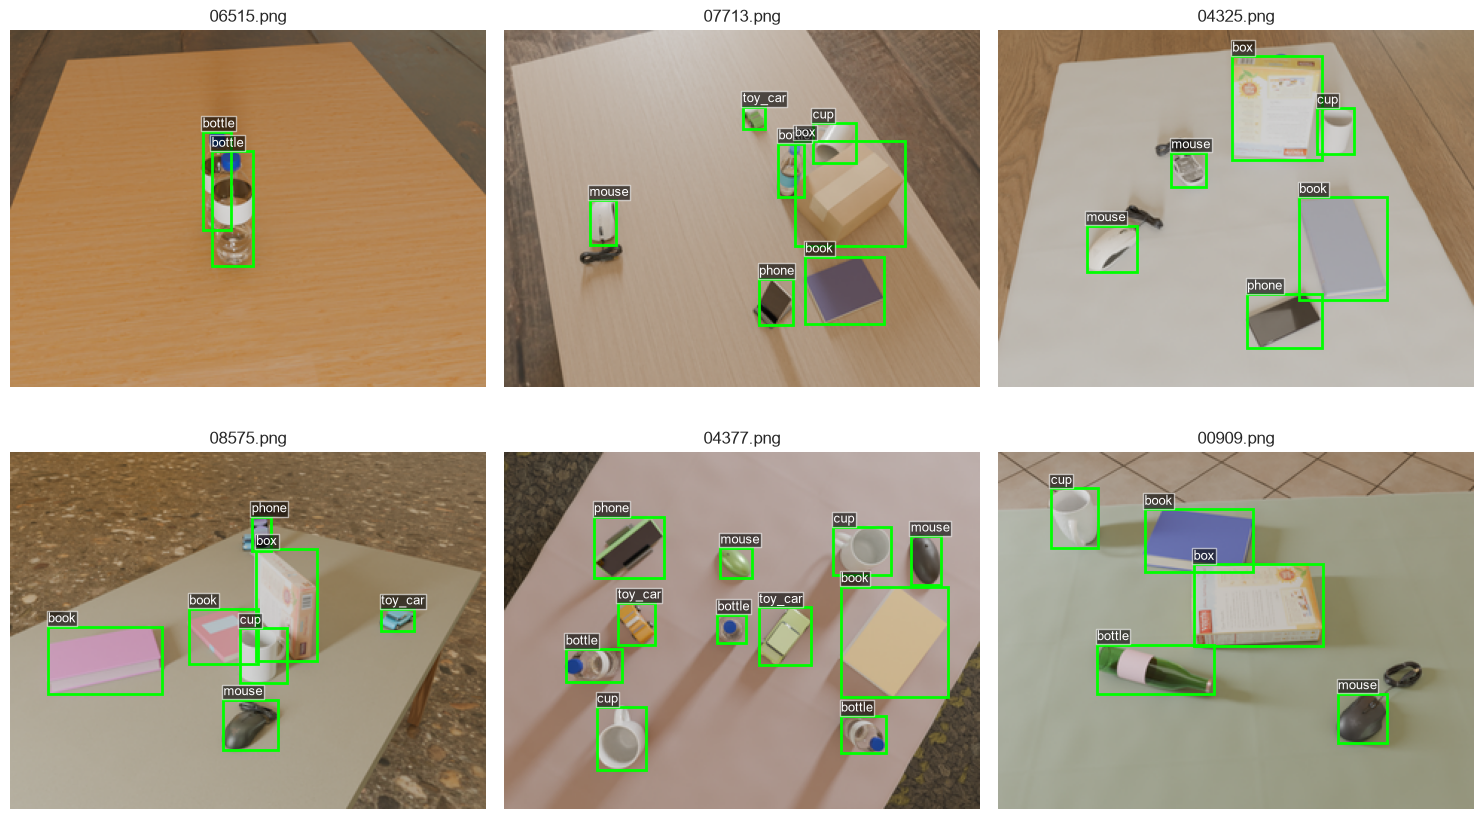

In [7]:
from matplotlib.patches import Rectangle

def show_labeled_images(n=6, seed=42):
    rng = np.random.default_rng(seed)
    paths = sorted(TRAIN_IMAGE_DIR.glob('*.png'))
    chosen = rng.choice(paths, size=min(n, len(paths)), replace=False)
    fig, axes = plt.subplots(2, 3, figsize=(15, 9))
    axes = np.atleast_1d(axes).ravel()
    for ax, image_path in zip(axes, chosen):
        image = Image.open(image_path).convert('RGB')
        ax.imshow(image)
        width, height = image.size
        rows = boxes_df[boxes_df['file'] == f'{image_path.stem}.txt']
        for _, row in rows.dropna(subset=['cx']).iterrows():
            x = (row.cx - row.w / 2) * width
            y = (row.cy - row.h / 2) * height
            rect = Rectangle((x, y), row.w * width, row.h * height, fill=False, linewidth=2, edgecolor='lime')
            ax.add_patch(rect)
            ax.text(x, max(0, y - 3), row.class_name, color='white', fontsize=9, bbox=dict(facecolor='black', alpha=.6, pad=1))
        ax.set_title(image_path.name)
        ax.axis('off')
    for ax in axes[len(chosen):]: ax.axis('off')
    plt.tight_layout()
    plt.show()

show_labeled_images()

## 5. Kết luận cần kiểm tra sau khi chạy

- Dùng bảng `label_counts` để xác định intent mất cân bằng và cân nhắc stratified split/class weights.
- Nếu `missing_count` khác 0, cần quyết định loại bỏ hoặc bổ sung giá trị trước khi train.
- `label_errors` phải rỗng; các bbox có tọa độ ngoài `[0, 1]`, kích thước không dương hoặc class id ngoài `classes.txt` cần được sửa.
- Quan sát ảnh mẫu để phát hiện nhãn lệch vị trí, ảnh lỗi hoặc khác biệt giữa quy ước tên file ảnh và file nhãn.